In [1]:
import matplotlib.pyplot as plt
import numpy as np 
from scipy.optimize import curve_fit

In [2]:
def f_(x): 

    I = integrate.quad(lambda t: t**2 / (np.exp(t) - 1), 0, x)[0]

    return  x**2 / I


In [3]:
# functions to plot on final plot 
# https://docs.scipy.org/doc/scipy-1.18.0/tutorial/integrate.html

# f(1.1) = 2.928
# f(7.5) = 23.799 (23.80)

import scipy.integrate as integrate 


# Debye Temp 
Td_C = 340    # Copper
Td_S = 1000   # Sapphire 

# Thermal conductivity to normalize (looking up values)
k_sapph = 82 # (for T = 200)
k_copp = 398 # (for T = 300)


def sapp_theor(T):

    # needing to normalize 
    N = k_sapph / np.exp(Td_S/ (2 * 200))

    return N * np.exp( Td_S / (2 * T))


def f_(x): 
    I = integrate.quad(lambda t: t**2 / (np.exp(t) - 1), 0, x)[0]
    return  x**2 / I

def f(T): 
    W = k_copp / f_(Td_C/300)

    return W * f_(Td_C/ T)



In [4]:

def lin(x, m, c): 
    return m * x + c 


In [5]:
def S_interp(temperatures):
    S_out = []
    T_table = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 18, 20,
     22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 45, 50, 55, 60, 65,
     70, 75, 80, 85, 90, 100, 120, 140, 160, 180, 200, 250, 273.15, 295]
    S_table = [np.nan, np.nan, 0.99, 1.35, 1.69, 2.01, 2.30, 2.59, 2.86, 3.12, 3.63, 4.12, 4.61, 5.09, 5.58,
     6.06, 6.55, 7.03, 7.52, 7.99, 8.46, 8.92, 9.37, 9.81, 10.23, 11.24, 12.17, 13.03, 13.82, 14.58,
     15.30, 16.01, 16.70, 17.38, 18.05, 19.37, 21.93, 24.42, 26.85, 29.18, 31.42, 36.58, 38.72, 40.42]
    for T in temperatures:
        if T < T_table[0] or T > T_table[-1]:
            S_out.append(float("nan"))
            continue
        for i in range(len(T_table) - 1):
            if T_table[i] <= T <= T_table[i + 1]:
                T0, T1 = T_table[i], T_table[i + 1]
                S0, S1 = S_table[i], S_table[i + 1]
                S_out.append(S0 + (S1 - S0) * (T - T0) / (T1 - T0))
                break
    return S_out[0]

In [6]:
# Thermocouples ∆V = SAB(T)∆T
Temp = np.array([3,4,5,6,7,8,9,10,12,14,16,18,20,22,24,26,28,30,32,34,36,38,40,45,50,55,60,65,70,75,85,90,100,120,140,160,180,200,250,273.15,295])
S_AB = np.array([0.99,1.35,1.69,2.01,2.30,2.59,2.86,3.12,3.63,4.12, 4.61, 5.09, 5.58, 6.06, 6.55, 7.03, 7.52, 7.99, 8.46, 8.92, 9.37, 9.81, 10.23, 11.24, 12.17, 13.03, 13.82, 14.58, 15.30, 16.01, 16.70, 17.38, 18.05, 19.37, 21.93, 24.42, 26.85, 29.18, 31.42, 38.72, 40.42])

def S(t): 
    i = np.where(Temp == t)[0][0]
    return S_AB[i]

# finding dT from dV:

def dT(dV, S):
    return dV / S
    
# errors via quadrature, with S_err: 
def dT_err_S(dV, S, dV_err, S_err):  
    return np.sqrt( ( dV_err / S) ** 2 + ((dV * S_err )/ (S ** 2) ) ** 2 )

# errors via quadrature (just error in dV)
def dt_err(S, dV_err):
    return dV_err / S


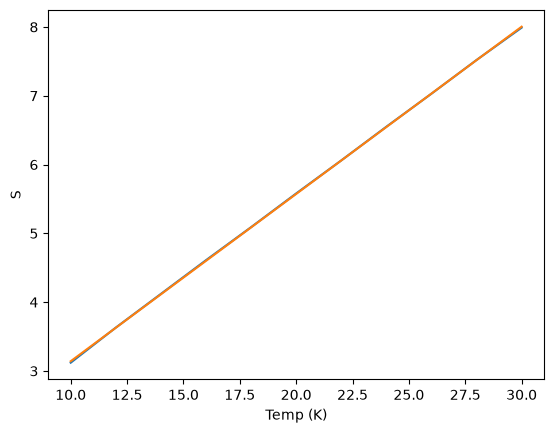

S(T=15) = 4.36 +- 0.01


In [7]:
# fitting S for T = 15 (roughly linear between T = 10 and T = 30 )
i_1 = np.where(Temp == 10)[0][0]
i_2 = np.where(Temp == 30)[0][0]

param, param_cov = curve_fit(lin, Temp[i_1: i_2 + 1], S_AB[i_1: i_2 +1])
m, c = param
m_err, c_error = np.sqrt(np.diag(param_cov))[0], np.sqrt(np.diag(param_cov))[1]


plt.plot(Temp[i_1: i_2 + 1], S_AB[i_1: i_2 +1])
plt.plot(Temp[i_1: i_2 + 1], lin(Temp[i_1: i_2 +1], m, c))
plt.xlabel('Temp (K)') 
plt.ylabel('S')
plt.show()

T = 15
T_err = 0 
# adding error in quadrature: 
S_err = np.sqrt( (T * m_err )** 2 + (m * T_err)** 2 + (c_error) ** 2)

print(f'S(T=15) = {round(lin(T, m, c),2)} +- {round(S_err,2)}')



In [8]:
# calculating cross sectional area (mm2)

# copper: 
r_C = 1.90 / 2 * 1e-3
r_C_err = 0.025  * 1e-3

A_C = np.pi * (r_C ** 2) 
A_C_err = 2 * np.pi * r_C * r_C_err  #error in quadrature 

# sapphire 
r_S = (3 / 2 ) * 1e-3
r_S_err = 0.025 * 1e-3

A_S = np.pi * (r_S ** 2)
A_S_err = 2 * np.pi * r_S * r_S_err #error in quadrature 

# distance (mm) between thermocouple junctions (cross section A above)
dx_C = 29.50 * 1e-3
dx_C_err = 0.05 * 1e-3

dx_S = 30.20 * 1e-3
dx_S_err = 0.05 * 1e-3


In [9]:
# measurement 1 : Room Temperature 
 
# set point temperature 
T_1 = 295.0

# seedbeck coefficient
S_b_1 =  S_interp([T_1]) 
print(S_b_1)    #S(T_ref)

# power: -----------------------
voltage_copper_1  = np.array([0, 0.469, 0.65, 1.09, 1.544, 2.163 ])  
voltage_sapphire_1 = np.array([0, 0.62, 0.83, 1.32, 2.00, 1.905 ]) 

current_copper_1 = np.array([0, 0.010, 0.014, 0.024, 0.035, 0.043 ])
current_sapphire_1 = np.array([0, 0.010, 0.015, 0.024, 0.035, 0.043 ])

P_C_1 = voltage_copper_1 * current_copper_1   # error in power should result from resolution of equipment and be smaller than error from T
P_S_1 = voltage_sapphire_1 * current_sapphire_1 
# voltages + error -------------

# copper 
dV_C_1 = np.array([0, 4.9000e-06, 9.5200e-06, 2.6113e-05, 5.1408e-05, 7.6891e-05])
dV_C_err_1 = np.array([5.7074e-08, 9.8973e-08, 6.3574e-08, 1.3008e-07, 3.1376e-07, 3.9295e-07 ])

# sapphire 
dV_S_1 = np.array([0, 2.5278e-05, 4.5418e-05, 1.1291e-04, 2.3264e-04, 3.4305e-04])
dV_S_err_1 = np.array([6.0724e-08, 2.0133e-07, 1.7213e-07, 1.9489e-07, 2.0376e-07, 2.6316e-07 ])

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_1 = dV_C_1 / S_b_1
dT_C_err_1 = dV_C_err_1 / S_b_1

dT_S_1 = dV_S_1 / S_b_1
dT_S_err_1 = dV_S_err_1 / S_b_1


40.42


In [10]:
# measurement 2: 15K
 
# set point temperature 
T_2 = 15

# seedbeck coefficient
S_b_2 =  S_interp([T_2])     #S(T_ref)
print(T_2)

# power: -----------------------
voltage_copper_2  = np.array([0,  ])
voltage_sapphire_2 = np.array([0, ])

current_copper_2 = np.array([0,  ])
current_sapphire_2 = np.array([0,  ])

P_C_2 = voltage_copper_2 * current_copper_2   # error in power should result from resolution of equipment and be smaller than error from T
P_S_2 = voltage_sapphire_2 * current_sapphire_2 
# voltages + error -------------

# copper 
dV_C = np.array([])
dV_C_err = np.array([])

# sapphire 
dV_S = np.array([])
dV_S_err = np.array([])

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C = dV_C / S_b
dT_C_err = dV_C_err / S_b

dT_S = dV_S / S_b
dT_S_err = dV_S_err / S_b

15


NameError: name 'S_b' is not defined

In [ ]:
# finding K (thermal conductivity from gradient) P = ( k A / dx ) * (dT)
# to include errors in dT, fitting dT = (dx /(kA)) * P

 # dx_C and A_C (and S) same for every measurement 

def k_and_plot(P_C, P_S, dT_C, dT_S, dT_C_err, dT_S_err): 

    p, pcov = curve_fit(lin, P_C, dT_C, sigma = dT_C_err, absolute_sigma= True)
    a_C, b_C = p
    a_C_err = np.sqrt(np.diag(pcov))[0]

    K_C = (dx_C) / ( (A_C) * a_C)
    print(a_C)

    K_C_error = np.sqrt( ( dx_C_err / (A_C * a_C) ) ** 2 + ((dx_C * a_C_err ) / (A_C * a_C**2)) **2 + ( (dx_C * A_C_err)/ (a_C * A_C**2))**2) 



    p, pcov = curve_fit(lin, P_S, dT_S, sigma = dT_S_err, absolute_sigma= True)
    a_S, b_S = p
    a_S_err = np.sqrt(np.diag(pcov))[0]

    K_S = (dx_S ) / ( (A_S) * a_S)
    K_S_error = np.sqrt( ( dx_S_err / (A_S * a_S) ) ** 2 + ((dx_S * a_S_err ) / (A_S * a_S**2)) **2 + ( (dx_S * A_S_err)/ (a_S * A_S**2))**2) 

    plt.errorbar(P_C, dT_C, yerr = dT_C_err, fmt = 'o', label = 'copper')
    plt.plot(P_C, lin(P_C, a_C, b_C), label = 'copper fitted')

    plt.errorbar(P_S, dT_S, yerr = dT_S_err, fmt = 'o', label = 'sapphire')
    plt.plot(P_S, lin(P_S, a_S, b_S), label = 'sapphire fitted')
    plt.legend()
    plt.show()

    plt.scatter(P_C, dT_C - lin(P_C, a_C, b_C), label = 'residuals copper' )
    plt.scatter(P_S, dT_S - lin(P_S, a_S, b_S), label = 'residuals sapphire' )

    return K_C, K_C_error, K_S, K_S_error



2.2436287999597633e-05


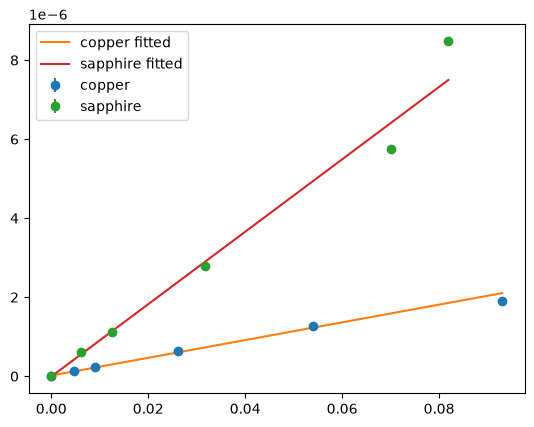

K (Copper) at room temp : 463739326.11590207+- 33364491.44133493
 K (Sapphire) at room temp :46623908.80421099+- 1556299.209695591 


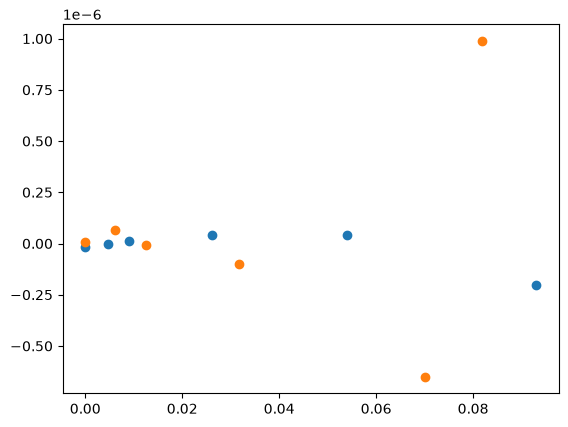

In [14]:
K_C1, K_C_err1, K_S1, K_S_err1 = k_and_plot(P_C_1, P_S_1, dT_C_1, dT_S_1, dT_C_err_1, dT_S_err_1)

print(f"K (Copper) at room temp : {K_C1}+- {K_C_err1}\n K (Sapphire) at room temp :{K_S1}+- {K_S_err1} ")


K_copper = [K_C1]
K_copper_err = [K_C_err1]
K_sapphire = [K_S1]
K_sapphire_err = [K_S_err1]
T = []

Plotting Thermal conductivity vs T


In [ ]:
x_values = np.linspace(15, 300, 500, endpoint = True)

plt.errorbar( T, K_copper, yerr = K_copper_err, fmt = 'o', label = 'copper')
plt.errorbar( T, K_sapphire, yerr = K_sapphire_err, fmt = 'o', label = 'sapphire')

plt.plot(x_values, [f(x) for x in x_values], label = 'total phonon density function')
plt.plot(x_values, sapp_theor(x_values), label = 'theoretical K for dielectrics (40K < T < Td)')
plt.xlabel("Temperature")
plt.ylabel(r"Thermal Conductivity, k (${Wm^{-1}K^{-1}}$)")
plt.ylim(0, 1000)
plt.legend()
plt.show()
